In [1]:
# 写一个代码用于清除csv文件的citations列
import pandas as pd
encoding = "utf-8"
csv_path = "/Users/ruyi/Desktop/NAIP/dataset/arxiv_cs_metadata.csv"  
df = pd.read_csv(csv_path, encoding=encoding)
if "citations" in df.columns:
    df = df.drop(columns=["citations"])
output_path = csv_path
df.to_csv(output_path, index=False, encoding=encoding)



In [2]:
# ... existing code ...

import pandas as pd

csv_path = "/Users/ruyi/Desktop/NAIP/dataset/arxiv_cs_metadata.csv"
df = pd.read_csv(csv_path)

# 查看前几行数据
display(df.head())

# 查看列名、非空数量和数据类型
df.info()

# 数值/分类列的统计信息
display(df.describe(include="all"))

# 每列缺失值统计
display(df.isna().sum())

# 查看部分关键列的取值分布（可按需增加/修改列名）
for col in ["primary_category", "authors", "year"]:
    if col in df.columns:
        display(df[col].value_counts().head(10))

# ... rest of code ...

,arxiv_id,category,title,abstract,published
0,2207.00473v3,cs.AI,Assessing the Effects of Hyperparameters on Kn...,Embedding knowledge graphs into low-dimensiona...,2022-07-01
1,2207.03227v2,cs.AI,Challenges and Pitfalls of Bayesian Unlearning,Machine unlearning refers to the task of remov...,2022-07-07
2,2207.03341v3,cs.AI,Softmax-free Linear Transformers,Vision transformers (ViTs) have pushed the sta...,2022-07-05
3,2207.03342v1,cs.AI,Monkeypox Skin Lesion Detection Using Deep Lea...,The recent monkeypox outbreak has become a pub...,2022-07-06
4,2207.04113v1,cs.AI,Seasonal Encoder-Decoder Architecture for Fore...,Deep learning (DL) in general and Recurrent ne...,2022-07-08


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11997 entries, 0 to 11996
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   arxiv_id   11997 non-null  object
 1   category   11997 non-null  object
 2   title      11997 non-null  object
 3   abstract   11997 non-null  object
 4   published  11997 non-null  object
dtypes: object(5)
memory usage: 468.8+ KB


,arxiv_id,category,title,abstract,published
count,11997,11997,11997,11997,11997
unique,10329,3,10329,10329,897
top,2303.16133v2,cs.AI,Exposing and Addressing Cross-Task Inconsisten...,As general purpose vision models get increasin...,2024-03-11
freq,3,3999,3,3,59


arxiv_id     0
category     0
title        0
abstract     0
published    0
dtype: int64

In [3]:

df = pd.read_csv(csv_path)

df["arxiv_id_base"] = df["arxiv_id"].str.replace(r"v\d+$", "", regex=True)
df["published"] = pd.to_datetime(df["published"], errors="coerce")
df = (
    df.sort_values("published", ascending=False)
      .drop_duplicates(subset="arxiv_id_base", keep="first")
      .drop(columns=["arxiv_id_base"])
)

df["title"] = (
    df["title"].astype(str)
    .str.replace(r"[\u201c\u201d]", '"', regex=True)
    .str.replace(r"[\u2018\u2019]", "'", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
df["abstract"] = (
    df["abstract"].astype(str)
    .str.replace(r"[\u201c\u201d]", '"', regex=True)
    .str.replace(r"[\u2018\u2019]", "'", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

cleaned_path = "/Users/ruyi/Desktop/NAIP/dataset/arxiv_cs_metadata_uni.csv"
df.to_csv(cleaned_path, index=False)


In [4]:
# ... existing code ...

df = df.sample(frac=1, random_state=42).reset_index(drop=True)
random_path = "/Users/ruyi/Desktop/NAIP/dataset/arxiv_cs_metadata_ran.csv"
df.to_csv(random_path, index=False)

# ... rest of code ...

In [5]:
df = pd.read_csv(cleaned_path)
df["published"] = pd.to_datetime(df["published"], errors="coerce")

# 分析标题、摘要长度以及发表时间特征
df["title_len"] = df["title"].str.len()
df["abstract_len"] = df["abstract"].str.len()
display(df[["title_len", "abstract_len"]].describe())

df["year"] = df["published"].dt.year
df["month"] = df["published"].dt.month

# 每年论文数量
display(df.groupby("year")["arxiv_id"].count().rename("paper_count_per_year"))

# 按年月统计
df["year_month"] = df["published"].dt.to_period("M")
display(df.groupby("year_month")["arxiv_id"].count().rename("paper_count_per_month"))

# 标题、摘要长度 Top 示例
display(df.nlargest(5, "title_len")[["arxiv_id", "title_len", "title"]])
display(df.nlargest(5, "abstract_len")[["arxiv_id", "abstract_len", "abstract"]])


,title_len,abstract_len
count,10329.000000,10329.000000
mean,78.809275,1230.247943
std,23.423368,318.442687
min,12.000000,96.000000
25%,63.000000,1012.000000
50%,77.000000,1218.000000
75%,93.000000,1445.000000
max,219.000000,3091.000000


year
2022    3533
2023    3403
2024    3393
Name: paper_count_per_year, dtype: int64

year_month
2022-01    265
2022-02     78
2022-03     71
2022-04     99
2022-05    107
2022-06    170
2022-07    524
2022-08    262
2022-09    322
2022-10    650
2022-11    646
2022-12    339
2023-01     70
2023-02     94
2023-03    552
2023-04    116
2023-05     60
2023-06     15
2023-07    341
2023-08    181
2023-09    318
2023-10    547
2023-11    616
2023-12    493
2024-01    501
2024-02    563
2024-03    752
2024-04    507
2024-05     60
2024-06     93
2024-07     69
2024-08    234
2024-09    381
2024-10    193
2024-11     40
Freq: M, Name: paper_count_per_month, dtype: int64

,arxiv_id,title_len,title
4130,2311.12041v1,219,Automated Detection of hidden Damages and Impu...
2742,2402.05571v1,209,Traditional Machine Learning Models and Bidire...
1665,2403.18537v1,207,A Path Towards Legal Autonomy: An interoperabl...
620,2409.00323v1,206,From Prediction to Application: Language Model...
7546,2211.11521v1,203,"Un discours et un public ""Gilets Jaunes"" au co..."


,arxiv_id,abstract_len,abstract
5348,2309.02812v1,3091,Most seismic risk assessment methods focus on ...
4927,2310.08908v1,1920,The large language model (LLM) has garnered si...
7744,2211.08143v1,1920,Selecting an appropriate task is challenging f...
7959,2210.12640v2,1920,Emotional support conversation (ESC) task can ...
8865,2208.09142v1,1920,Given a learning problem with real-world trade...


=== title_len ===


count    10329.000000
mean        78.809275
std         23.423368
min         12.000000
10%         50.000000
25%         63.000000
50%         77.000000
75%         93.000000
90%        109.000000
95%        120.000000
99%        141.000000
max        219.000000
Name: title_len, dtype: float64

=== abstract_len ===


count    10329.000000
mean      1230.247943
std        318.442687
min         96.000000
10%        827.000000
25%       1012.000000
50%       1218.000000
75%       1445.000000
90%       1666.000000
95%       1789.000000
99%       1905.720000
max       3091.000000
Name: abstract_len, dtype: float64

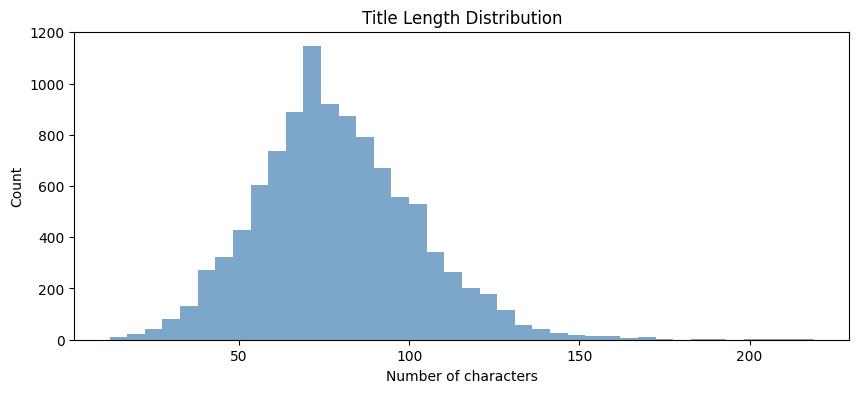

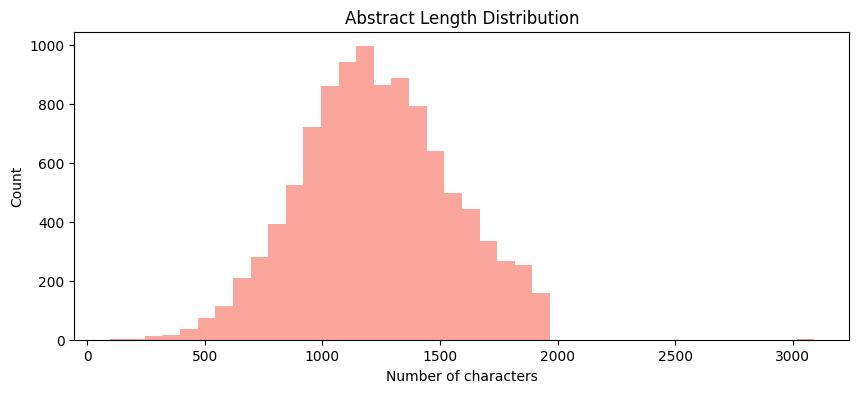

In [6]:
# 更细致的统计量与分位数
for col in ["title_len", "abstract_len"]:
    print(f"=== {col} ===")
    display(
        df[col].describe(
            percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
        )
    )

# 简单的直方图可视化
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
df["title_len"].plot(kind="hist", bins=40, alpha=0.7, color="steelblue")
plt.title("Title Length Distribution")
plt.xlabel("Number of characters")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(10, 4))
df["abstract_len"].plot(kind="hist", bins=40, alpha=0.7, color="salmon")
plt.title("Abstract Length Distribution")
plt.xlabel("Number of characters")
plt.ylabel("Count")
plt.show()

In [7]:
# ... existing code ...

min_title = df.loc[df["title_len"].idxmin(), ["arxiv_id", "title_len", "title"]]
max_title = df.loc[df["title_len"].idxmax(), ["arxiv_id", "title_len", "title"]]
display(pd.DataFrame([min_title, max_title], index=["Shortest Title", "Longest Title"]))

min_abstract = df.loc[df["abstract_len"].idxmin(), ["arxiv_id", "abstract_len", "abstract"]]
max_abstract = df.loc[df["abstract_len"].idxmax(), ["arxiv_id", "abstract_len", "abstract"]]
display(pd.DataFrame([min_abstract, max_abstract], index=["Shortest Abstract", "Longest Abstract"]))

# ... rest of code ...

,arxiv_id,title_len,title
Shortest Title,2410.09087v1,12,Mechanistic?
Longest Title,2311.12041v1,219,Automated Detection of hidden Damages and Impu...


,arxiv_id,abstract_len,abstract
Shortest Abstract,2401.01134v1,96,"This paper introduces HPC-Net, a high-precisio..."
Longest Abstract,2309.02812v1,3091,Most seismic risk assessment methods focus on ...


In [2]:
# 导入必要的库
import pandas as pd
import matplotlib.pyplot as plt
# import seaborn as sns

# 读取 CSV 文件
file_path = "/Users/ruyi/Desktop/NAIP/dataset/high_cited_papers.csv"  # 替换为你的文件路径
data = pd.read_csv(file_path)

# 检查是否存在 'citation_count' 列
if 'citation_count' not in data.columns:
    print("CSV 文件中没有 'citation_count' 列.")
else:
    # 显示 citation_count 的基本统计信息
    print("Citation Count 的基本统计信息:")
    print(data['citation_count'].describe())

    # # 绘制 citation_count 的分布直方图
    # plt.figure(figsize=(10, 6))
    # sns.histplot(data['citation_count'], bins=30, kde=True, color='skyblue')  # 使用 seaborn 绘图
    # plt.title("Citation Count 分布", fontsize=16)
    # plt.xlabel("Citation Count", fontsize=14)
    # plt.ylabel("频数", fontsize=14)
    # plt.grid(axis='y', linestyle='--', alpha=0.7)
    # plt.show()

    # # 绘制箱线图查看异常值
    # plt.figure(figsize=(8, 4))
    # sns.boxplot(x=data['citation_count'], color='orange')
    # plt.title("Citation Count 箱线图", fontsize=16)
    # plt.xlabel("Citation Count", fontsize=14)
    # plt.show()

Citation Count 的基本统计信息:
count     5998.000000
mean       393.711237
std       1237.382437
min         51.000000
25%         51.000000
50%         51.000000
75%        471.750000
max      74707.000000
Name: citation_count, dtype: float64
